# Matched-Pair Mentor Demo — MFCC / LFCC / CQCC on Real vs. TTS-Synthesised Speech

**Cross-Lingual Audio Deepfake Detection in Indic Languages**
Parv Shah (23BCE219) · Divya Patel (23BCE227) · Dept. of CSE, Nirma University, Ahmedabad

---

## Why this notebook exists

Our earlier exploratory notebook (`rmsdhoni (1).ipynb` / `Rms1try_features_v2_fixed.ipynb`) compared
**unrelated** clips: English bonafide from ASVspoof 2019, Gujarati fake from IndicSynth, Gujarati real
from FLEURS. Different speakers, different sentences, different recording chains, and — as the numbers
below show — wildly different clip lengths. Any visual difference in the MFCC/LFCC/CQCC heatmaps could
therefore have been caused by *content*, *speaker*, *microphone*, or *duration* rather than by the thing
we actually care about: **the synthesis artefact**.

Measured from that notebook's own stored output (frame counts → clip durations, `n_fft=400`,
`hop_length=160`, `center=False`):

| Category | n | mean duration | range |
|---|---|---|---|
| English – Real (ASVspoof bonafide) | 5 | 3.42 s | 2.81 – 4.39 s |
| English – Fake (ASVspoof spoof) | 5 | 2.40 s | 1.41 – 4.16 s |
| Gujarati – Fake (IndicSynth) | 5 | 5.44 s | 4.78 – 6.62 s |
| Gujarati – Real (FLEURS `gu_in`) | 5 | 11.44 s | 7.74 – 16.98 s |

Gujarati *real* clips were on average **2.10×** longer than Gujarati *fake* clips, and the Gujarati
material overall was **2.90×** longer than the English material. That is a textbook confound.

## What this notebook does differently

1. **Same spoken text on both sides.** Every fake clip is a TTS rendering of the *exact transcript* of
   the real clip it is paired with. Content is held constant, so the residual difference is synthesis.
2. **Same duration everywhere.** All 20 clips are cropped/padded to a fixed **4.0 s** at 16 kHz before
   any feature is computed. Duration is removed as a variable.
3. **Same speaker gender per pair.** The TTS voice is chosen to match the FLEURS speaker's `gender`
   label, removing the most obvious remaining speaker-level confound.
4. **Correct time axes.** The original notebook called `librosa.display.specshow(data, x_axis="time")`
   without passing `sr`/`hop_length`, so librosa fell back to its own defaults (`sr=22050`,
   `hop_length=512`). Each frame was drawn as 512/22050 = 23.22 ms instead of 160/16000 = 10 ms, so
   every heatmap's time axis was stretched by a factor of **2.32**. Fixed here by passing
   `sr=16000, hop_length=160` explicitly.
5. **A line plot, not just heatmaps.** For each feature we add an overlaid *mean-coefficient* plot
   (Real vs Fake), which is far easier to read than comparing heatmap textures by eye.

> **Scope.** This notebook is **diagnostic/exploratory**. 5 clips per category is nowhere near enough
> to train or evaluate a classifier. Nothing here is a detection result. Formal evaluation still
> requires the full Triple-Branch ResNeXt training + EER protocol from the project roadmap.

## 1. Install & import dependencies

In [5]:
%pip install -U torchaudio librosa scipy soundfile huggingface_hub datasets edge-tts gTTS

Defaulting to user installation because normal site-packages is not writeable
  Using cached scipy-1.18.0-cp313-cp313-win_amd64.whl.metadata (61 kB)
  Using cached click-8.4.2-py3-none-any.whl.metadata (2.6 kB)
INFO: pip is looking at multiple versions of gtts to determine which version is compatible with other requirements. This could take a while.
  Using cached gTTS-2.5.4-py3-none-any.whl.metadata (4.1 kB)
INFO: pip is still looking at multiple versions of gtts to determine which version is compatible with other requirements. This could take a while.
INFO: This is taking longer than usual. You might need to provide the dependency resolver with stricter constraints to reduce runtime. See https://pip.pypa.io/warnings/backtracking for guidance. If you want to abort this run, press Ctrl + C.
Using cached scipy-1.18.0-cp313-cp313-win_amd64.whl (36.6 MB)
   ---------------------------------------- 0.0/793.2 kB ? eta -:--:--
   ---------------------------------------  786.4/793.2 kB 4.1 MB

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mlxtend 0.24.0 requires numpy>=2.3.5, but you have numpy 2.1.3 which is incompatible.
sklearn-compat 0.1.3 requires scikit-learn<1.7,>=1.2, but you have scikit-learn 1.8.0 which is incompatible.

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import os
import io
import json
import glob
import random
import time
import asyncio
import threading
import warnings

import torch
import torchaudio
import librosa
import librosa.display
import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.fftpack import dct

warnings.filterwarnings("ignore")

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

TARGET_SR = 16000
N_CLIPS_PER_CATEGORY = 5

# --- Fixed clip duration -------------------------------------------------------------------
# 4.0 s. Long enough to contain several words / a dozen-plus phonemes, so the cepstral averages
# are not dominated by a single vowel; short enough that 20 clips x 3 features stay light to
# compute and plot. At 16 kHz this is exactly 64,000 samples -> 398 MFCC/LFCC frames
# (n_fft=400, hop_length=160, center=False) and 401 CQCC frames, identical for every clip.
CLIP_SECONDS = 4.0
TARGET_LEN = int(CLIP_SECONDS * TARGET_SR)

OUT_DIR = "demo_audio"                              # full-length real + synthetic clips
ANALYSED_DIR = os.path.join(OUT_DIR, "analysed_4s")  # the exact 4.0 s waveforms the plots describe
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(ANALYSED_DIR, exist_ok=True)

print(f"torch {torch.__version__} | torchaudio {torchaudio.__version__} | librosa {librosa.__version__}")
print(f"Fixed clip length: {CLIP_SECONDS} s = {TARGET_LEN} samples @ {TARGET_SR} Hz")

torch 2.13.0+cpu | torchaudio 2.11.0+cpu | librosa 1.0.0
Fixed clip length: 4.0 s = 64000 samples @ 16000 Hz


## 2. Sources — and an explicit substitution

| Category | Source | Why |
|---|---|---|
| **English – Real** | Google **FLEURS `en_us`** (test split) | *substituted*, see below |
| **English – Fake** | `edge-tts` `en-US-*` neural voice, same transcript | matched pair |
| **Gujarati – Real** | Google **FLEURS `gu_in`** (test split) | same source as the exploratory notebook |
| **Gujarati – Fake** | `edge-tts` `gu-IN-*` neural voice, same transcript | matched pair |

### ⚠️ Substitution: ASVspoof 2019 → FLEURS `en_us` for the English-real side

The exploratory notebook drew English bonafide speech from `Bisher/ASVspoof_2019_LA`. That mirror
carries `audio`, `key` (bonafide/spoof), speaker and system-ID columns — **but no transcript text**.
ASVspoof 2019 is built on VCTK and does not ship per-utterance transcriptions in this mirror, and the
whole point of this notebook is to synthesise the *exact same words* on the fake side. Without a
transcript that is impossible.

Following the fallback specified for this deliverable, the English-real side therefore uses
**FLEURS `en_us`**, which exposes a `transcription` / `raw_transcription` field, exactly like the
Gujarati `gu_in` config already used. This has a pleasant side effect: both languages now come from the
*same* corpus, recorded under the same protocol, so the English↔Gujarati comparison is no longer
confounded by corpus either.

The trade-off, stated plainly: the English fakes in this notebook are **our own edge-tts renderings**,
not ASVspoof's 19 attack systems (A01–A19). This notebook is therefore *not* a substitute for
evaluating on ASVspoof — that remains the job of the base-training phase of the roadmap. It is a
controlled illustration of what a synthesis artefact looks like in cepstral space.

### ⚠️ Note on IndicSynth

The exploratory notebook used IndicSynth for Gujarati fakes. IndicSynth clips are TTS renderings of
*their own* text, unrelated to any FLEURS utterance, so they cannot form a matched pair. They are
deliberately not used here. IndicSynth remains the Gujarati fake corpus for the actual training phase.

### A note on audio decoding

`datasets` ≥ 4.0 decodes the `Audio` feature eagerly through **torchcodec**, which in turn needs
FFmpeg's shared libraries to be present. That is true on Colab, but not on every machine. To keep this
notebook runnable anywhere, each stream is cast with `Audio(decode=False)`: the loader then hands back
the raw `{"bytes", "path"}` payload and we decode it ourselves with `soundfile`. FLEURS ships 16 kHz
WAV, which `soundfile` reads natively, so nothing is lost — and the notebook no longer depends on an
FFmpeg installation.

In [7]:
from datasets import load_dataset, Audio

FLEURS_CONFIGS = {"English": "en_us", "Gujarati": "gu_in"}


def open_fleurs(cfg):
    """Open one FLEURS config as a byte-yielding stream. Called fresh on every retry:
    once the HTTP client behind a streaming dataset has been closed by a network drop,
    the iterator cannot be resumed, so the dataset must be reopened rather than reused."""
    stream = load_dataset("google/fleurs", cfg, split="test", streaming=True)
    # Hand back raw bytes instead of a torchcodec-decoded object (see note above).
    return stream.cast_column("audio", Audio(decode=False))


for lang, cfg in FLEURS_CONFIGS.items():
    print(f"FLEURS {cfg} will be opened on demand (streaming=True -> nothing downloaded yet).")

FLEURS en_us will be opened on demand (streaming=True -> nothing downloaded yet).
FLEURS gu_in will be opened on demand (streaming=True -> nothing downloaded yet).


## 3. Pick 5 real clips per language — with their transcripts

Same streaming + `shuffle(seed=42, buffer_size=...)` pattern as the exploratory notebook, with one
addition: from the shuffled buffer we keep only utterances of **at least `CLIP_SECONDS`** (so the
4 s crop is never padded with silence on the real side) and then take the **5 shortest** of those.

The buffer and scan are both set to **40** utterances. FLEURS embeds roughly 0.6 MB of audio per row,
and a streaming shuffle must fill its whole buffer before yielding anything, so a 200-row buffer means
downloading ~120 MB per language before the first clip appears. 40 keeps the selection randomised while
letting the notebook run in minutes rather than tens of minutes.

Why the shortest? Because the fake side is TTS of the *whole* transcript. If we picked a 17 s
utterance, its 4 s crop would cover roughly the first quarter of the sentence — and a TTS voice with a
different speaking rate would cover a different fraction of that same sentence in its own 4 s. Choosing
short utterances keeps the two 4 s windows covering as close to the same words as practically possible.
This residual rate mismatch is noted as a limitation at the end of the notebook.

In [8]:
import itertools


def select_fleurs_matched(stream, n=5, seed=42, buffer_size=40, scan=40, min_seconds=CLIP_SECONDS):
    """Scan a bounded, shuffled slice of a streaming FLEURS split and return the n shortest
    utterances that are still at least `min_seconds` long. Each returned record keeps the (undecoded)
    audio, the transcript text (needed for the matched TTS pair) and the speaker gender label."""
    shuffled = stream.shuffle(seed=seed, buffer_size=buffer_size)
    gender_names = getattr(stream.features.get("gender"), "names", ["male", "female", "other"])

    cands = []
    for ex in itertools.islice(shuffled, scan):
        n_samples = ex.get("num_samples")
        if n_samples is None:
            continue
        dur = n_samples / 16000.0          # FLEURS audio is distributed at 16 kHz
        if dur < min_seconds:
            continue
        g = ex.get("gender")
        g = gender_names[g] if isinstance(g, int) and g < len(gender_names) else str(g)
        text = (ex.get("raw_transcription") or ex.get("transcription") or "").strip()
        if not text:
            continue
        cands.append({"audio": ex["audio"], "text": text, "gender": g,
                      "duration": dur, "id": ex.get("id")})

    if len(cands) < n:
        raise ValueError(f"Only {len(cands)} usable utterances found in {scan} scanned examples")
    cands.sort(key=lambda r: r["duration"])
    return cands[:n]


MAX_ATTEMPTS = 4

real_clips = {}
for lang, cfg in FLEURS_CONFIGS.items():
    for attempt in range(1, MAX_ATTEMPTS + 1):
        try:
            # Reopen the stream on every attempt: a mid-iteration network drop closes the
            # underlying HTTP client, and the same stream object cannot then be resumed.
            real_clips[lang] = select_fleurs_matched(open_fleurs(cfg), n=N_CLIPS_PER_CATEGORY)
            break
        except Exception as e:
            print(f"  [{lang}] attempt {attempt}/{MAX_ATTEMPTS} failed: {type(e).__name__}: {e}")
            if attempt < MAX_ATTEMPTS:
                time.sleep(10 * attempt)
    if lang not in real_clips:
        print(f"Skipping {lang} - Real: all {MAX_ATTEMPTS} attempts failed")
        continue
    print(f"\n=== {lang} - Real ({len(real_clips[lang])} clips) ===")
    for i, r in enumerate(real_clips[lang], 1):
        snippet = r["text"][:70] + ("..." if len(r["text"]) > 70 else "")
        print(f"  clip {i}: {r['duration']:6.2f}s  gender={r['gender']:<6} text={snippet}")


=== English - Real (5 clips) ===
  clip 1:   5.36s  gender=male   text=But there are a lot of things about birds that still look like a dinos...
  clip 2:   5.64s  gender=female text=Virtual teams are held to the same standards of excellence as conventi...
  clip 3:   5.64s  gender=female text=In some areas boiling water for a minute is enough, in others several ...
  clip 4:   5.72s  gender=male   text=The Internet combines elements of both mass and interpersonal communic...
  clip 5:   5.76s  gender=female text=The cabbage juice changes color depending on how acidic or basic (alka...


'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/google/fleurs/resolve/70bb2e84b976b7e960aa89f1c648e09c59f894dd/parquet-data/gu_in/test-00000-of-00001.parquet
Retrying in 1s [Retry 1/5].
'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/google/fleurs/resolve/70bb2e84b976b7e960aa89f1c648e09c59f894dd/parquet-data/gu_in/test-00000-of-00001.parquet
Retrying in 2s [Retry 2/5].
'[Errno 11001] getaddrinfo failed' thrown while requesting GET https://huggingface.co/datasets/google/fleurs/resolve/70bb2e84b976b7e960aa89f1c648e09c59f894dd/parquet-data/gu_in/test-00000-of-00001.parquet
Retrying in 4s [Retry 3/5].



=== Gujarati - Real (5 clips) ===
  clip 1:   4.32s  gender=male   text=તે મારિયાની નીચે પાતળું અને ઊંચાઈની નીચે જાડું હોય.
  clip 2:   5.40s  gender=male   text=રાસાયણિકમાં હાઇડ્રોજનની શક્તિના આધારે કોબીનો રસ રંગ બદલાય.
  clip 3:   5.88s  gender=male   text=સિંહો સૌથી વધુ સામાજિક બિલાડીઓ છે, જે ગૌરવ નામે ઓળખાતા મોટા જૂથમાં રહે...
  clip 4:   6.84s  gender=male   text=આ રસાયણનું pH કહેવાય છે. તમે લાલ કોબીજનો રસ વાપરીને સૂચક બનાવી શકો છો.
  clip 5:   6.90s  gender=female text=મહિલાઓ: એવી સલાહ છે કે કોઈ પણ મહિલા મુસાફરે તે પરિણીત છે તેમ જ કહેવું,...


## 4. Synthesise the matched fakes

For each real clip we hand its **exact transcript** to a neural TTS voice of the **same language and
the same gender** as the original speaker. `edge-tts` (Microsoft Edge's free neural voices) is used
because it is one of the very few free engines with a genuine `gu-IN` neural voice; `gTTS` is kept as a
fallback if `edge-tts` cannot reach its endpoint.

`edge-tts` is asynchronous and returns MP3. The helper below runs the coroutine on its own event loop
in a worker thread (so it behaves identically in Colab, JupyterLab and a plain script), then transcodes
the MP3 to a 16 kHz mono WAV so every downstream cell sees the same file type.

In [9]:
TTS_VOICES = {
    ("English", "female"):  "en-US-AriaNeural",
    ("English", "male"):    "en-US-GuyNeural",
    ("Gujarati", "female"): "gu-IN-DhwaniNeural",
    ("Gujarati", "male"):   "gu-IN-NiranjanNeural",
}
GTTS_LANG = {"English": "en", "Gujarati": "gu"}


def run_async(coro):
    """Run an asyncio coroutine from anywhere (notebook with a live loop, or plain script)."""
    box = {}

    def _runner():
        try:
            box["value"] = asyncio.run(coro)
        except BaseException as e:      # re-raised on the calling thread below
            box["error"] = e

    t = threading.Thread(target=_runner)
    t.start()
    t.join()
    if "error" in box:
        raise box["error"]
    return box["value"]


def mp3_to_wav16k(mp3_path, wav_path):
    y, _ = librosa.load(mp3_path, sr=TARGET_SR, mono=True)
    sf.write(wav_path, y, TARGET_SR, subtype="PCM_16")
    return wav_path


def synthesize(text, lang, gender, out_stem):
    """Render `text` with a neural TTS voice matching `lang`/`gender`.
    Returns (wav_path, engine_name, voice_name)."""
    mp3_path, wav_path = out_stem + ".mp3", out_stem + ".wav"
    voice = TTS_VOICES.get((lang, gender)) or TTS_VOICES[(lang, "female")]

    # Retry edge-tts before falling back. A transient DNS/connection blip on one clip
    # would otherwise synthesise that clip with a *different engine* from its neighbours,
    # planting an engine confound inside a group this whole design exists to keep uniform.
    for attempt in range(1, 4):
        try:
            import edge_tts
            run_async(edge_tts.Communicate(text, voice).save(mp3_path))
            if os.path.getsize(mp3_path) == 0:
                raise RuntimeError("edge-tts produced an empty file")
            return mp3_to_wav16k(mp3_path, wav_path), "edge-tts", voice
        except Exception as e:
            print(f"    edge-tts attempt {attempt}/3 failed ({type(e).__name__}: {e})")
            if attempt < 3:
                time.sleep(5 * attempt)

    print("    falling back to gTTS for this clip -- NOTE the engine mismatch flagged below")
    from gtts import gTTS
    gTTS(text=text, lang=GTTS_LANG[lang]).save(mp3_path)
    return mp3_to_wav16k(mp3_path, wav_path), "gTTS", GTTS_LANG[lang]


fake_clips = {}
for lang, clips in real_clips.items():
    fake_clips[lang] = []
    print(f"\n=== {lang} - Fake (TTS of the same transcripts) ===")
    for i, r in enumerate(clips, 1):
        stem = os.path.join(OUT_DIR, f"{lang.lower()}_fake_{i}")
        try:
            wav, engine, voice = synthesize(r["text"], lang, r["gender"], stem)
            dur = sf.info(wav).duration
            fake_clips[lang].append({"audio": wav, "text": r["text"], "gender": r["gender"],
                                     "duration": dur, "engine": engine, "voice": voice})
            print(f"  clip {i}: {dur:6.2f}s  {engine} / {voice}  (real was {r['duration']:.2f}s)")
        except Exception as e:
            print(f"  clip {i} FAILED: {type(e).__name__}: {e}")
    engines = {c["engine"] for c in fake_clips[lang]}
    if len(engines) > 1:
        print(f"  !! WARNING: {lang} fakes span multiple TTS engines {engines} -- that is an "
              f"engine confound inside one group; re-run to obtain a uniform set.")
    elif engines:
        print(f"  all {lang} fakes synthesised with a single engine: {engines.pop()}")


=== English - Fake (TTS of the same transcripts) ===
  clip 1:   4.44s  edge-tts / en-US-GuyNeural  (real was 5.36s)
  clip 2:   6.96s  edge-tts / en-US-AriaNeural  (real was 5.64s)
  clip 3:   5.88s  edge-tts / en-US-AriaNeural  (real was 5.64s)
  clip 4:   5.18s  edge-tts / en-US-GuyNeural  (real was 5.72s)
  clip 5:   6.58s  edge-tts / en-US-AriaNeural  (real was 5.76s)
  all English fakes synthesised with a single engine: edge-tts

=== Gujarati - Fake (TTS of the same transcripts) ===
  clip 1:   5.09s  edge-tts / gu-IN-NiranjanNeural  (real was 4.32s)
  clip 2:   5.71s  edge-tts / gu-IN-NiranjanNeural  (real was 5.40s)
  clip 3:   7.32s  edge-tts / gu-IN-NiranjanNeural  (real was 5.88s)
  clip 4:   7.97s  edge-tts / gu-IN-NiranjanNeural  (real was 6.84s)
  clip 5:   9.41s  edge-tts / gu-IN-DhwaniNeural  (real was 6.90s)
  all Gujarati fakes synthesised with a single engine: edge-tts


## 5. Fixed-duration crop / pad

`load_waveform` keeps the exploratory notebook's logic and branch structure (filepath / legacy HF audio
dict / torchcodec `AudioDecoder`, stereo→mono, resample to 16 kHz). Two branches are **added** for
portability, not changed: an undecoded `{"bytes","path"}` payload is read via `soundfile`, and a plain
file path falls back to `soundfile` if `torchaudio.load` cannot reach torchcodec/FFmpeg. On Colab the
original `torchaudio.load` path is still the one that runs.

`fix_duration` is the genuinely new part: head crop to exactly `TARGET_LEN` samples, zero-padding at the
end only if a clip is somehow shorter.

In [10]:
def _sf_read(source):
    """Decode a path or an in-memory buffer with soundfile -> (waveform[C,N], sr)."""
    y, sr = sf.read(source, dtype="float32", always_2d=True)
    return torch.tensor(y.T), sr


def load_waveform(item, target_sr=TARGET_SR):
    """Accepts a filepath (str), an undecoded HF audio dict {'bytes','path'}, a legacy HF
    audio dict {'array','sampling_rate'}, or a `datasets` torchcodec AudioDecoder (recent
    `datasets` versions decode audio lazily via torchcodec instead of eager numpy arrays)."""
    if isinstance(item, str):
        try:
            waveform, sr = torchaudio.load(item)
        except Exception:
            # torchaudio >= 2.9 routes load() through torchcodec, which needs FFmpeg's
            # shared libraries. Fall back to soundfile so the notebook runs without them.
            waveform, sr = _sf_read(item)
    elif isinstance(item, dict) and item.get("bytes") is not None:
        # Undecoded HF Audio payload (see the Audio(decode=False) cast in section 2).
        waveform, sr = _sf_read(io.BytesIO(item["bytes"]))
    elif isinstance(item, dict) and "array" in item:
        waveform = torch.tensor(np.asarray(item["array"]), dtype=torch.float32).unsqueeze(0)
        sr = item["sampling_rate"]
    elif hasattr(item, "get_all_samples"):
        # torchcodec.decoders.AudioDecoder (used by recent `datasets` Audio feature)
        samples = item.get_all_samples()
        waveform = samples.data
        if not isinstance(waveform, torch.Tensor):
            waveform = torch.tensor(np.asarray(waveform), dtype=torch.float32)
        waveform = waveform.float()
        if waveform.dim() == 1:
            waveform = waveform.unsqueeze(0)
        sr = samples.sample_rate
    else:
        raise TypeError(f"Unsupported clip item type: {type(item)}")

    if waveform.shape[0] > 1:  # collapse stereo to mono
        waveform = waveform.mean(dim=0, keepdim=True)
    if sr != target_sr:
        resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=target_sr)
        waveform = resampler(waveform)
    return waveform


def fix_duration(waveform, target_len=TARGET_LEN):
    """Crop (from the start) or zero-pad (at the end) to exactly `target_len` samples,
    so duration is constant across all 20 clips and cannot act as a confound."""
    n = waveform.shape[-1]
    if n > target_len:
        return waveform[..., :target_len]
    if n < target_len:
        return torch.nn.functional.pad(waveform, (0, target_len - n))
    return waveform

### 5b. Write both halves of every pair to disk

The synthetic clips already exist as files, because that is how TTS output arrives. The real clips do
not — they are streamed from FLEURS straight into memory. That is inconvenient for anyone who wants to
*listen* to a pair rather than read its spectrogram, so this cell writes the human side out as well and
records a manifest.

After this cell `demo_audio/` contains, for each language and each pair index:

| File | What it is |
|---|---|
| `{lang}_real_{i}.wav` | the human FLEURS recording, full length, 16 kHz mono |
| `{lang}_fake_{i}.wav` | the TTS rendering of that same transcript, full length |
| `{lang}_fake_{i}.mp3` | the raw TTS output before transcoding |
| `pairs.csv` | transcript, speaker gender, TTS engine and voice, and both durations |

Play `{lang}_real_1.wav` and `{lang}_fake_1.wav` back to back and you are hearing the same sentence
twice — once spoken, once synthesised. That is the comparison the rest of the notebook measures.

In [11]:
manifest = []

for lang in real_clips:
    for i, r in enumerate(real_clips[lang], 1):
        # Write the human side out at the same 16 kHz mono the extractor sees.
        w = load_waveform(r["audio"])
        real_path = os.path.join(OUT_DIR, f"{lang.lower()}_real_{i}.wav")
        sf.write(real_path, w.squeeze().numpy(), TARGET_SR, subtype="PCM_16")
        r["saved_path"] = real_path

        f = fake_clips.get(lang, [])[i - 1] if i <= len(fake_clips.get(lang, [])) else None
        manifest.append({
            "language": lang,
            "pair": i,
            "gender": r["gender"],
            "real_file": os.path.basename(real_path),
            "real_duration_s": round(r["duration"], 2),
            "fake_file": os.path.basename(f["audio"]) if f else "",
            "fake_duration_s": round(f["duration"], 2) if f else "",
            "tts_engine": f["engine"] if f else "",
            "tts_voice": f["voice"] if f else "",
            "transcript": r["text"],
        })

pairs_df = pd.DataFrame(manifest)
pairs_csv = os.path.join(OUT_DIR, "pairs.csv")
pairs_df.to_csv(pairs_csv, index=False, encoding="utf-8-sig")   # utf-8-sig so Excel shows Gujarati

print(f"Wrote {len(manifest)} matched pairs to {OUT_DIR}/ and the manifest to {pairs_csv}\n")
print(pairs_df[["language", "pair", "gender", "real_file", "real_duration_s",
                "fake_file", "fake_duration_s", "tts_voice"]].to_string(index=False))

Wrote 10 matched pairs to demo_audio/ and the manifest to demo_audio\pairs.csv

language  pair gender           real_file  real_duration_s           fake_file  fake_duration_s            tts_voice
 English     1   male  english_real_1.wav             5.36  english_fake_1.wav             4.44      en-US-GuyNeural
 English     2 female  english_real_2.wav             5.64  english_fake_2.wav             6.96     en-US-AriaNeural
 English     3 female  english_real_3.wav             5.64  english_fake_3.wav             5.88     en-US-AriaNeural
 English     4   male  english_real_4.wav             5.72  english_fake_4.wav             5.18      en-US-GuyNeural
 English     5 female  english_real_5.wav             5.76  english_fake_5.wav             6.58     en-US-AriaNeural
Gujarati     1   male gujarati_real_1.wav             4.32 gujarati_fake_1.wav             5.09 gu-IN-NiranjanNeural
Gujarati     2   male gujarati_real_2.wav             5.40 gujarati_fake_2.wav             5.71 gu-IN

## 6. Feature extraction — MFCC, LFCC, CQCC

Transform definitions and the CQCC computation (CQT → dB → DCT, keep 13 coefficients) are reused
**exactly** as in the exploratory notebook: 16 kHz, `n_fft=400` (25 ms), `hop_length=160` (10 ms),
23 mel filters, 13 coefficients per feature, `center=False`.

In [12]:
mfcc_transform = torchaudio.transforms.MFCC(
    sample_rate=TARGET_SR,
    n_mfcc=13,
    melkwargs={"n_fft": 400, "hop_length": 160, "n_mels": 23, "center": False},
)

lfcc_transform = torchaudio.transforms.LFCC(
    sample_rate=TARGET_SR,
    n_lfcc=13,
    speckwargs={"n_fft": 400, "hop_length": 160, "center": False},
)

N_FFT = 400
HOP_LENGTH = 160


def extract_features(item):
    """Returns (mfcc, lfcc, cqcc) as 2D numpy arrays (n_coeffs, n_frames), computed on a
    waveform forced to exactly CLIP_SECONDS. `item` may be a clip reference (path / HF audio
    payload) or an already-prepared waveform tensor, so a caller that has decoded the audio
    for another purpose does not have to decode it twice."""
    waveform = item if isinstance(item, torch.Tensor) else fix_duration(load_waveform(item))

    mfcc = mfcc_transform(waveform).squeeze(0).numpy()
    lfcc = lfcc_transform(waveform).squeeze(0).numpy()

    waveform_np = waveform.squeeze().numpy()
    cqt_spectrogram = np.abs(librosa.cqt(waveform_np, sr=TARGET_SR, hop_length=HOP_LENGTH))
    log_cqt = librosa.amplitude_to_db(cqt_spectrogram, ref=np.max)
    cqcc = dct(log_cqt, type=2, axis=0, norm="ortho")[:13]

    return mfcc, lfcc, cqcc

## 7. Run extraction over all 20 clips

Four categories × 5 clips. Because every waveform is forced to 4.0 s first, **every** feature matrix
comes out the same shape — which is exactly the property the exploratory notebook lacked.

Each cropped waveform is also written to `demo_audio/analysed_4s/`, so the audio on disk is byte-for-byte
the audio the heatmaps and line plots below are computed from — not merely the same clip at a different
length.

In [13]:
CATEGORIES = ["English - Real", "English - Fake", "Gujarati - Real", "Gujarati - Fake"]

clip_sets = {}
for lang in ("English", "Gujarati"):
    if lang in real_clips:
        clip_sets[f"{lang} - Real"] = real_clips[lang]
    if lang in fake_clips:
        clip_sets[f"{lang} - Fake"] = fake_clips[lang]

features = {}   # features[category][i] = {"mfcc":..., "lfcc":..., "cqcc":...}

for category in CATEGORIES:
    if category not in clip_sets:
        print(f"Skipping {category}: no clips")
        continue
    features[category] = []
    for idx, rec in enumerate(clip_sets[category]):
        try:
            # Decode once: the same 4.0 s waveform is both saved and fed to the extractor,
            # so the audio on disk is exactly the audio the plots below describe.
            waveform = fix_duration(load_waveform(rec["audio"]))
            lang, kind = category.split(" - ")
            sf.write(os.path.join(ANALYSED_DIR, f"{lang.lower()}_{kind.lower()}_{idx+1}.wav"),
                     waveform.squeeze().numpy(), TARGET_SR, subtype="PCM_16")

            mfcc, lfcc, cqcc = extract_features(waveform)
            features[category].append({"mfcc": mfcc, "lfcc": lfcc, "cqcc": cqcc,
                                       "text": rec["text"]})
            print(f"OK  [{category}] clip {idx+1}  MFCC{mfcc.shape} LFCC{lfcc.shape} CQCC{cqcc.shape}")
        except Exception as e:
            print(f"FAILED [{category}] clip {idx+1}: {type(e).__name__}: {e}")

all_shapes = {f["mfcc"].shape for fs in features.values() for f in fs}
n_extracted = sum(len(fs) for fs in features.values())
print(f"\nExtracted {n_extracted} clips across {len(features)} categories")
print(f"Distinct MFCC shapes: {all_shapes}")
print(f"All {n_extracted} extracted clips share one identical shape:", len(all_shapes) == 1)

OK  [English - Real] clip 1  MFCC(13, 398) LFCC(13, 398) CQCC(13, 401)
OK  [English - Real] clip 2  MFCC(13, 398) LFCC(13, 398) CQCC(13, 401)
OK  [English - Real] clip 3  MFCC(13, 398) LFCC(13, 398) CQCC(13, 401)
OK  [English - Real] clip 4  MFCC(13, 398) LFCC(13, 398) CQCC(13, 401)
OK  [English - Real] clip 5  MFCC(13, 398) LFCC(13, 398) CQCC(13, 401)
OK  [English - Fake] clip 1  MFCC(13, 398) LFCC(13, 398) CQCC(13, 401)
OK  [English - Fake] clip 2  MFCC(13, 398) LFCC(13, 398) CQCC(13, 401)
OK  [English - Fake] clip 3  MFCC(13, 398) LFCC(13, 398) CQCC(13, 401)
OK  [English - Fake] clip 4  MFCC(13, 398) LFCC(13, 398) CQCC(13, 401)
OK  [English - Fake] clip 5  MFCC(13, 398) LFCC(13, 398) CQCC(13, 401)
OK  [Gujarati - Real] clip 1  MFCC(13, 398) LFCC(13, 398) CQCC(13, 401)
OK  [Gujarati - Real] clip 2  MFCC(13, 398) LFCC(13, 398) CQCC(13, 401)
OK  [Gujarati - Real] clip 3  MFCC(13, 398) LFCC(13, 398) CQCC(13, 401)
OK  [Gujarati - Real] clip 4  MFCC(13, 398) LFCC(13, 398) CQCC(13, 401)
OK

## 8. Heatmap grid — 4 categories × 5 clips, per feature

Same layout as the exploratory notebook, with the **time-axis bug fixed**: `sr=16000` and
`hop_length=160` are now passed to `librosa.display.specshow`, so the x-axis reads 0–4 s as it should
instead of librosa's default 22050 Hz / 512-hop interpretation.

Rows are ordered Real above Fake **within each language**, so each vertical pair is the matched pair —
the same sentence, spoken and then synthesised.

In [14]:
def plot_feature_grid(feature_name, cmap="magma"):
    categories = [c for c in CATEGORIES if len(features.get(c, [])) > 0]
    if not categories:
        print(f"No successfully extracted clips available to plot for '{feature_name}'.")
        return

    n_rows, n_cols = len(categories), N_CLIPS_PER_CATEGORY
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 2.6 * n_rows), squeeze=False)
    fig.suptitle(f"{feature_name.upper()} - {n_rows} categories x {n_cols} matched clips "
                 f"({CLIP_SECONDS:.0f}s each, 16 kHz)", fontsize=14)

    for row, category in enumerate(categories):
        clips = features[category]
        for col in range(n_cols):
            ax = axes[row][col]
            if col < len(clips):
                # FIX: pass sr and hop_length so the time axis is correct. The exploratory
                # notebook omitted both, so librosa assumed sr=22050 / hop_length=512 and
                # stretched every x-axis by 512/22050 / (160/16000) = 2.32x.
                librosa.display.specshow(clips[col][feature_name], x_axis="time",
                                         sr=TARGET_SR, hop_length=HOP_LENGTH, cmap=cmap, ax=ax)
            else:
                ax.axis("off")
            if col == 0:
                ax.set_ylabel(category, fontsize=9)
            if row == 0:
                ax.set_title(f"pair {col+1}", fontsize=9)
            if row < n_rows - 1:
                ax.set_xlabel("")

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

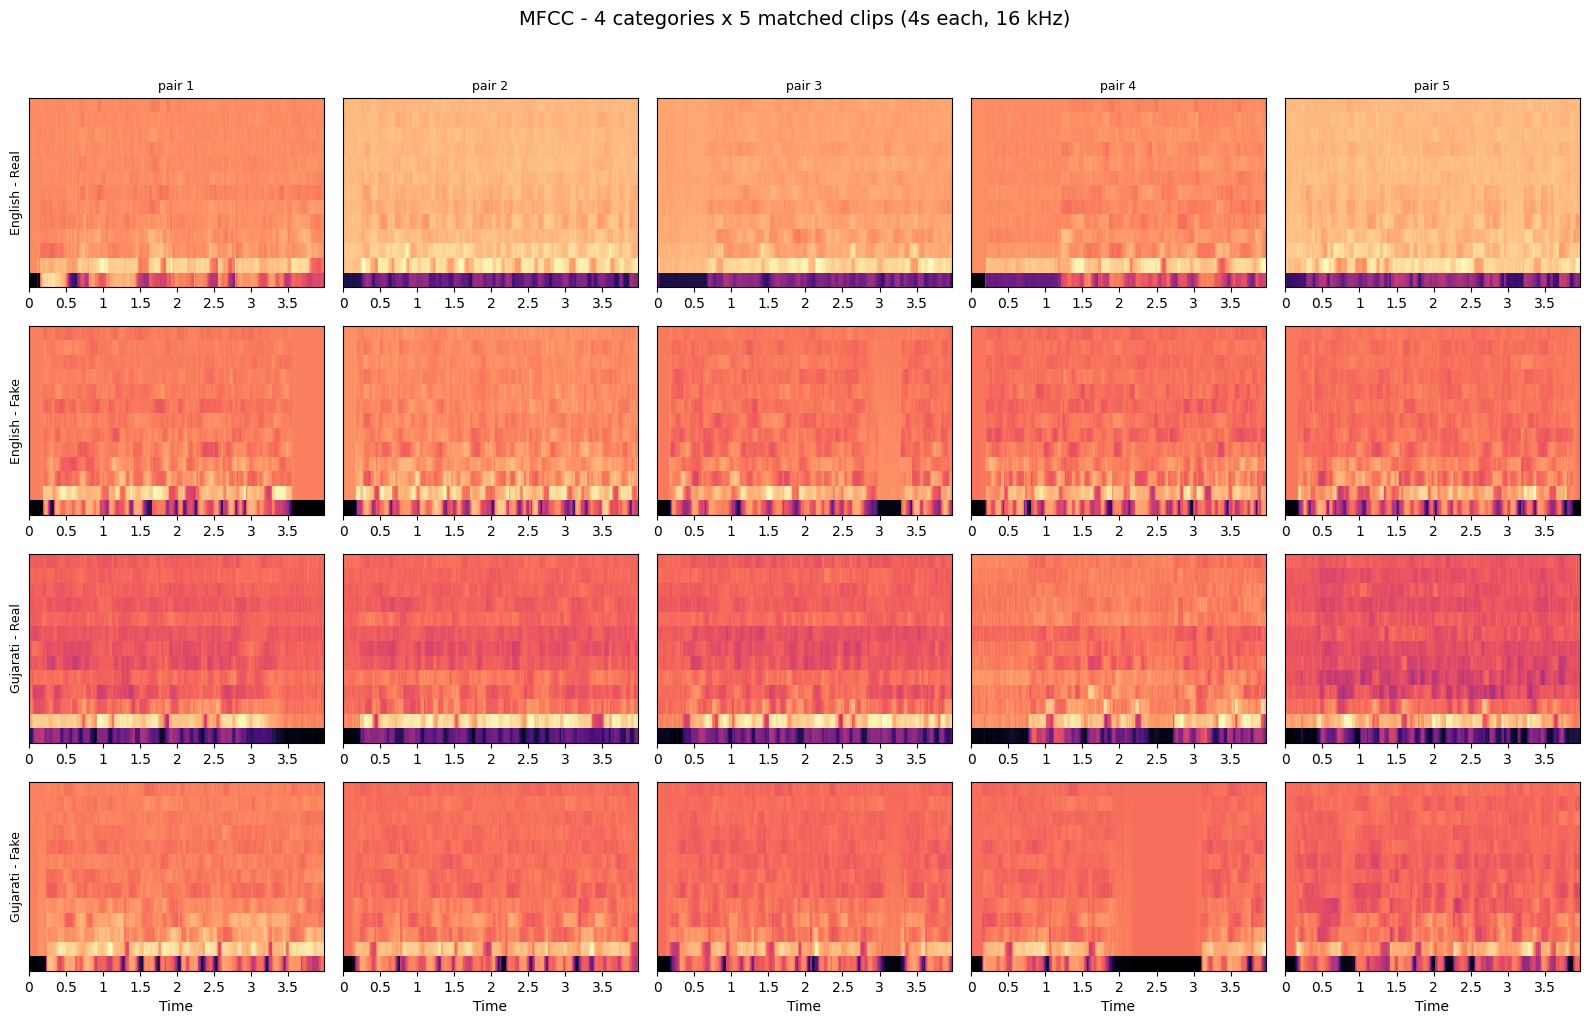

In [15]:
plot_feature_grid("mfcc")

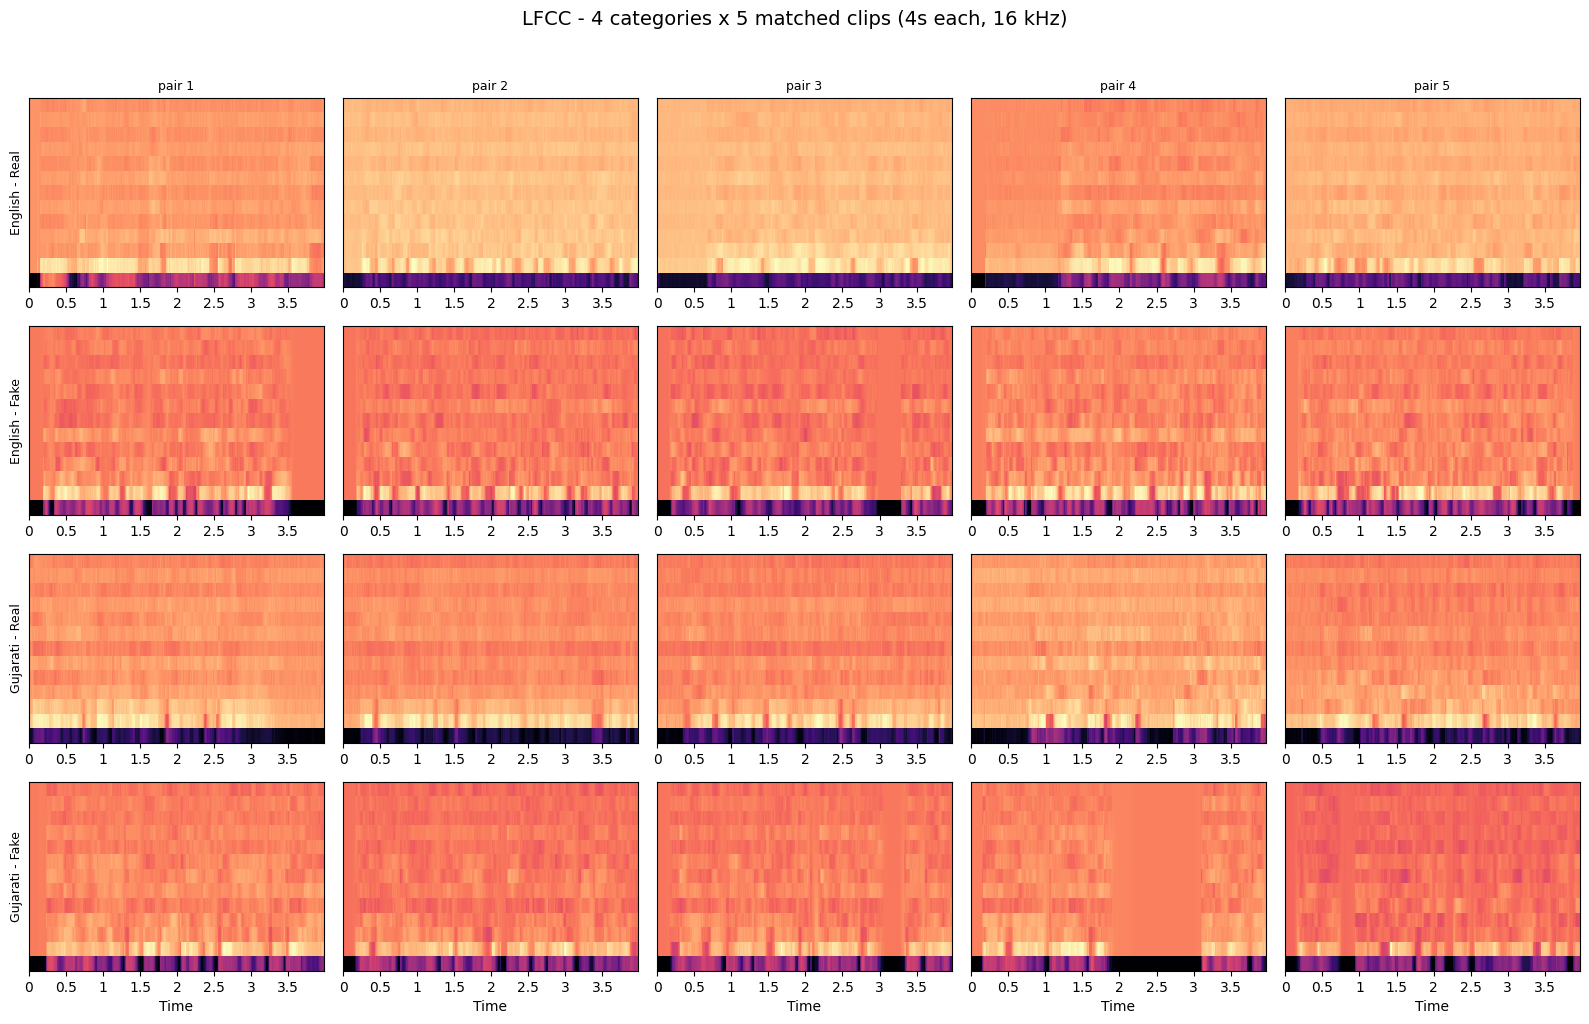

In [16]:
plot_feature_grid("lfcc")

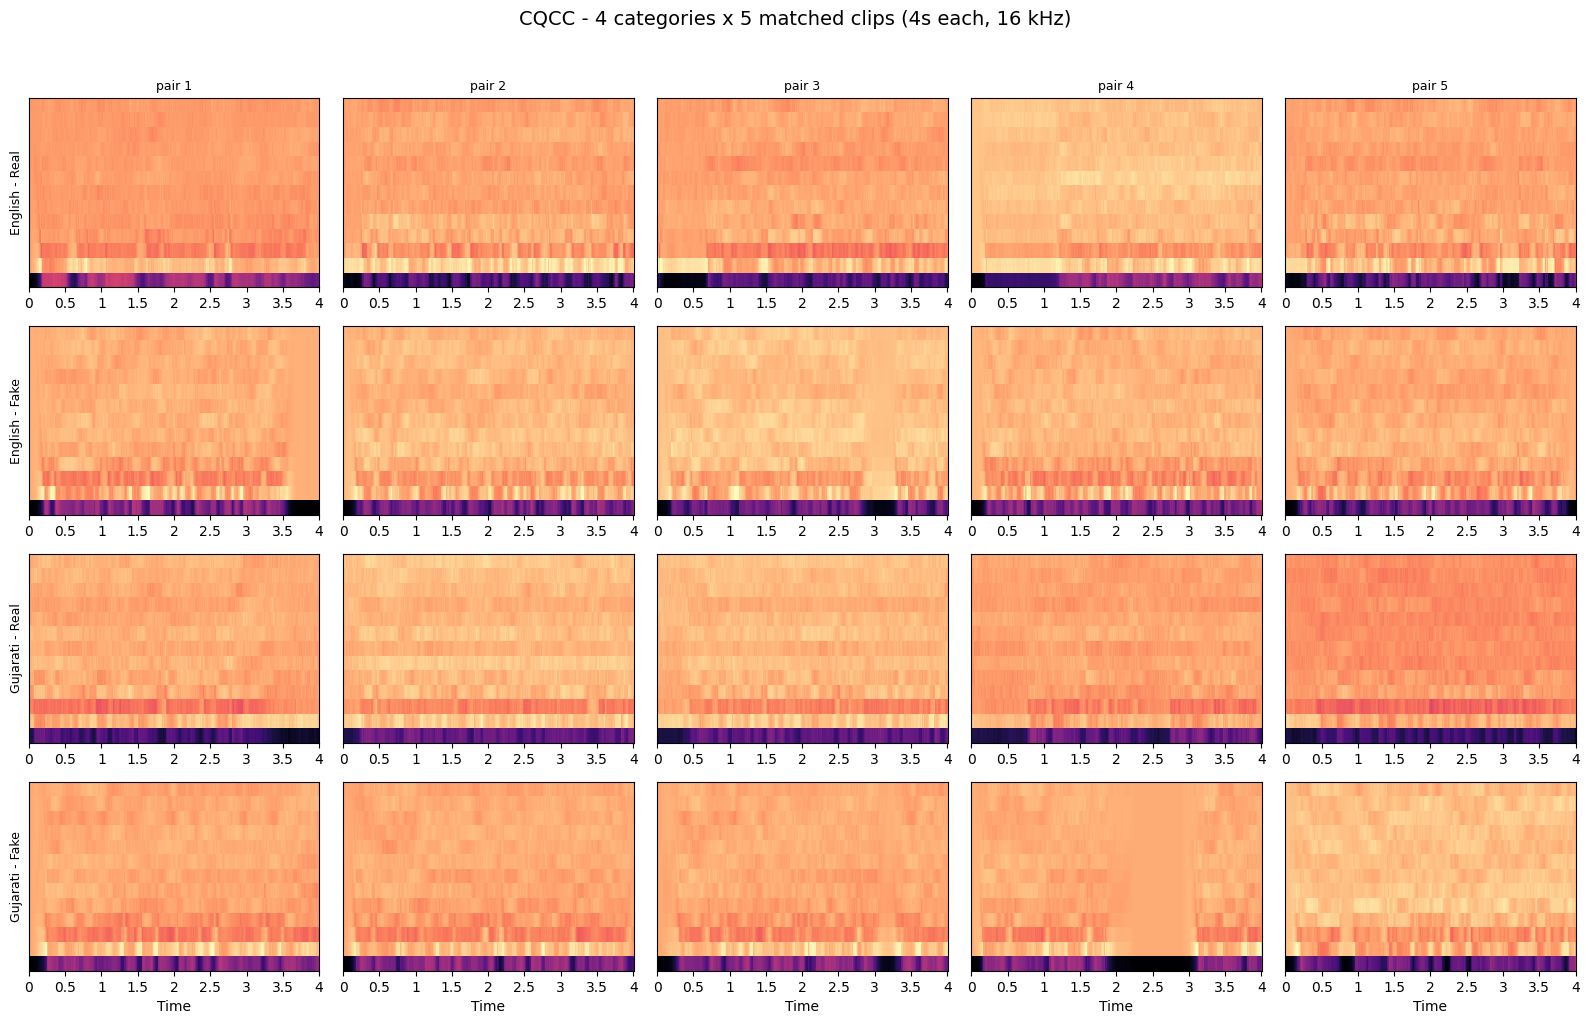

In [17]:
plot_feature_grid("cqcc")

## 9. The "prove it with a picture" plot — mean coefficient profiles

Each heatmap above is a 13 × 398 matrix, which is a lot to compare by eye. Collapse it: average each
coefficient row **over time**, then average **over the 5 clips**, and you get a single 13-point curve
per category. Plot Real and Fake on the same axes, per language.

The shaded band is ±1 standard deviation across the 5 clips — it shows whether a gap between the two
lines is bigger than the ordinary clip-to-clip variation, or lost inside it.

In [18]:
def mean_profile(category, feature_name):
    """(mean_over_clips, std_over_clips, per_clip_stack) of the time-averaged coefficient vector."""
    per_clip = np.stack([f[feature_name].mean(axis=1) for f in features[category]])  # (n_clips, 13)
    return per_clip.mean(axis=0), per_clip.std(axis=0), per_clip


def plot_mean_profiles(feature_name):
    langs = [l for l in ("English", "Gujarati")
             if features.get(f"{l} - Real") and features.get(f"{l} - Fake")]
    if not langs:
        print("Not enough categories to plot mean profiles.")
        return

    fig, axes = plt.subplots(1, len(langs), figsize=(6.5 * len(langs), 4.2), squeeze=False)
    idx = np.arange(13)

    for j, lang in enumerate(langs):
        ax = axes[0][j]
        for label, colour in (("Real", "#1f77b4"), ("Fake", "#d62728")):
            mu, sd, _ = mean_profile(f"{lang} - {label}", feature_name)
            ax.plot(idx, mu, marker="o", ms=4, lw=2, color=colour, label=f"{lang} {label}")
            ax.fill_between(idx, mu - sd, mu + sd, color=colour, alpha=0.15)
        ax.set_title(f"{lang} - mean {feature_name.upper()} per coefficient")
        ax.set_xlabel("coefficient index")
        ax.set_ylabel(f"mean {feature_name.upper()} value")
        ax.set_xticks(idx)
        ax.grid(alpha=0.3)
        ax.legend()

    fig.suptitle(f"{feature_name.upper()} - Real vs TTS-Fake, same text, same {CLIP_SECONDS:.0f}s, "
                 f"averaged over time and over {N_CLIPS_PER_CATEGORY} clips (band = +/-1 s.d.)",
                 fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()

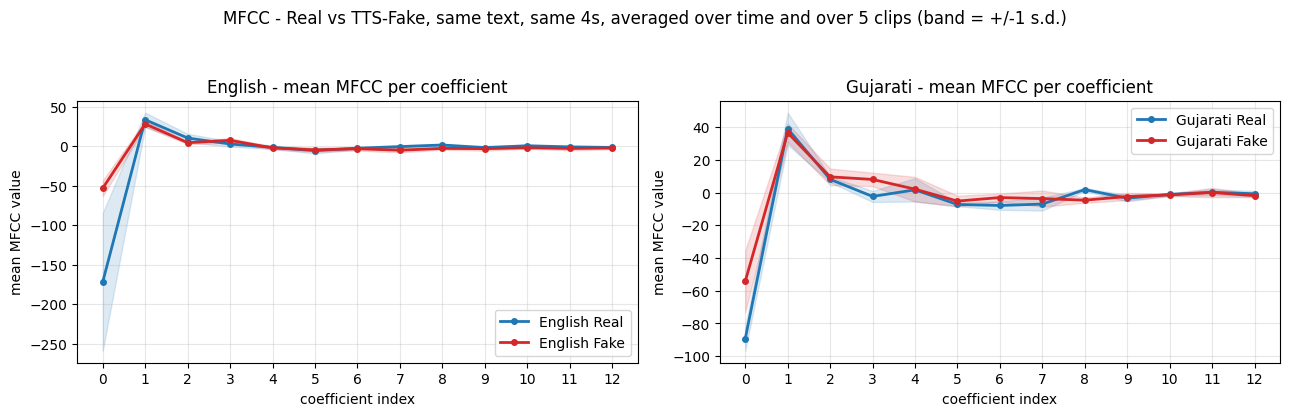

In [19]:
plot_mean_profiles("mfcc")

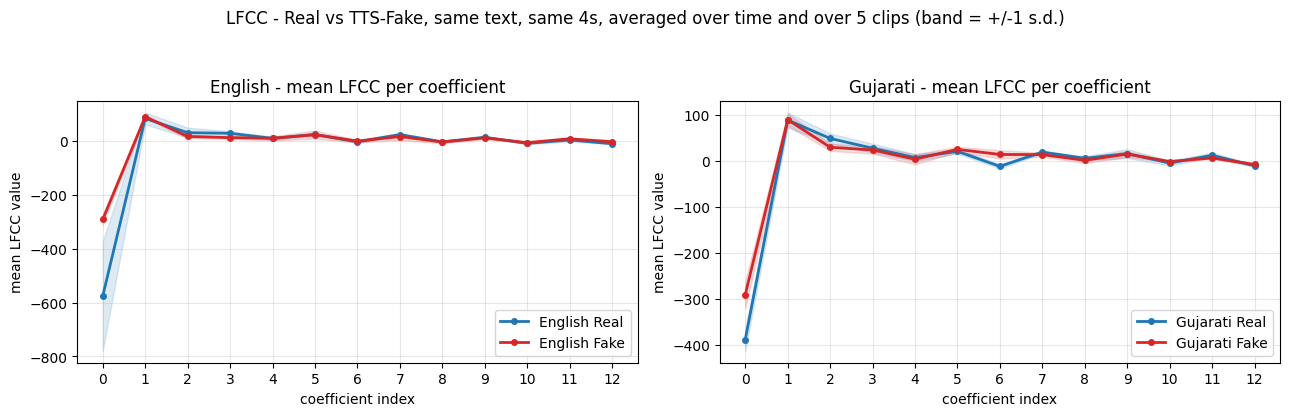

In [20]:
plot_mean_profiles("lfcc")

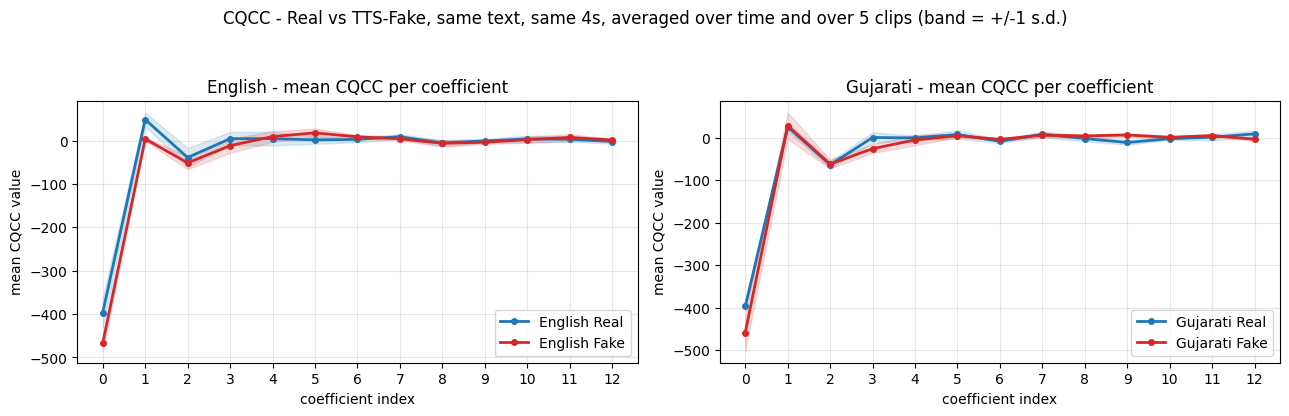

In [21]:
plot_mean_profiles("cqcc")

## 10. Putting numbers on the picture

Eyeballing two lines is not evidence. This cell quantifies, for every (language, feature, coefficient):

- **`|gap|`** — |mean(Real) − mean(Fake)|, in the feature's own units.
- **Cohen's *d*** — the gap divided by the pooled clip-to-clip standard deviation. This is the number
  that matters: it says how large the Real/Fake separation is *relative to the noise between clips*.
  With n = 5 per group these estimates are extremely noisy, so they are reported as descriptive
  effect sizes only, **not** as significance tests.
- **Nearest-centroid leave-one-out accuracy** on the 13-dim time-averaged vectors — a crude "is this
  even separable?" probe. 10 clips per language, so chance is 50%.

Everything printed here is written to `analysis/mentor_demo_metrics.json` so the paper can quote exact
values rather than approximations.

In [22]:
def cohens_d(a, b):
    """Effect size between two (n_clips, 13) stacks, per coefficient."""
    na, nb = a.shape[0], b.shape[0]
    pooled = np.sqrt(((na - 1) * a.var(axis=0, ddof=1) + (nb - 1) * b.var(axis=0, ddof=1))
                     / (na + nb - 2))
    pooled = np.where(pooled == 0, np.nan, pooled)
    return (a.mean(axis=0) - b.mean(axis=0)) / pooled


def loo_nearest_centroid(a, b):
    """Leave-one-out nearest-centroid accuracy on standardised 13-dim vectors. Chance = 0.5."""
    X = np.vstack([a, b])
    y = np.array([0] * len(a) + [1] * len(b))
    X = (X - X.mean(axis=0)) / (X.std(axis=0) + 1e-9)
    correct = 0
    for i in range(len(X)):
        mask = np.arange(len(X)) != i
        c0 = X[mask][y[mask] == 0].mean(axis=0)
        c1 = X[mask][y[mask] == 1].mean(axis=0)
        pred = 0 if np.linalg.norm(X[i] - c0) < np.linalg.norm(X[i] - c1) else 1
        correct += int(pred == y[i])
    return correct / len(X)


metrics = {"clip_seconds": CLIP_SECONDS, "sample_rate": TARGET_SR,
           "n_clips_per_category": N_CLIPS_PER_CATEGORY, "languages": {}}

for lang in ("English", "Gujarati"):
    rc, fc = f"{lang} - Real", f"{lang} - Fake"
    if not (features.get(rc) and features.get(fc)):
        continue
    metrics["languages"][lang] = {}
    print("\n" + "=" * 78 + f"\n{lang}\n" + "=" * 78)
    for feat in ("mfcc", "lfcc", "cqcc"):
        mu_r, sd_r, per_r = mean_profile(rc, feat)
        mu_f, sd_f, per_f = mean_profile(fc, feat)
        gap = np.abs(mu_r - mu_f)
        d = cohens_d(per_r, per_f)
        acc = loo_nearest_centroid(per_r, per_f)
        top = int(np.nanargmax(np.abs(d)))

        metrics["languages"][lang][feat] = {
            "mean_real": mu_r.round(4).tolist(),
            "mean_fake": mu_f.round(4).tolist(),
            "sd_real": sd_r.round(4).tolist(),
            "sd_fake": sd_f.round(4).tolist(),
            "abs_gap": gap.round(4).tolist(),
            "cohens_d": np.round(d, 4).tolist(),
            "max_abs_d_coeff": top,
            "max_abs_d": float(round(abs(d[top]), 4)),
            "mean_abs_d": float(round(float(np.nanmean(np.abs(d))), 4)),
            "n_coeffs_abs_d_gt_0p8": int(np.nansum(np.abs(d) > 0.8)),
            "loo_nearest_centroid_acc": acc,
        }

        print(f"\n  {feat.upper()}")
        header = f"    {'c':>3} {'mean(Real)':>12} {'mean(Fake)':>12} {'|gap|':>10} {'Cohens d':>11}"
        print(header)
        for c in range(13):
            print(f"    {c:>3} {mu_r[c]:>12.3f} {mu_f[c]:>12.3f} {gap[c]:>10.3f} {d[c]:>11.2f}")
        print(f"    -> largest |d| at coefficient {top} (|d| = {abs(d[top]):.2f}); "
              f"mean |d| over 13 coeffs = {np.nanmean(np.abs(d)):.2f}; "
              f"{int(np.nansum(np.abs(d) > 0.8))}/13 coeffs with |d| > 0.8")
        print(f"    -> leave-one-out nearest-centroid accuracy: {acc:.2f} (chance 0.50, n=10)")

os.makedirs("analysis", exist_ok=True)
with open("analysis/mentor_demo_metrics.json", "w", encoding="utf-8") as fh:
    json.dump(metrics, fh, indent=2)
print("\nWrote analysis/mentor_demo_metrics.json")


English

  MFCC
      c   mean(Real)   mean(Fake)      |gap|    Cohens d
      0     -171.811      -53.107    118.704       -1.71
      1       33.558       28.205      5.354        0.70
      2       10.432        4.507      5.925        1.31
      3        2.809        7.467      4.658       -1.34
      4       -1.398       -2.123      0.725        0.32
      5       -5.575       -4.659      0.917       -0.27
      6       -2.539       -3.163      0.623        0.29
      7       -0.500       -5.079      4.579        1.78
      8        1.574       -2.727      4.302        2.82
      9       -1.774       -3.054      1.280        0.47
     10        0.593       -1.938      2.530        1.77
     11       -0.797       -2.813      2.016        1.00
     12       -1.518       -2.242      0.724        0.43
    -> largest |d| at coefficient 8 (|d| = 2.82); mean |d| over 13 coeffs = 1.09; 7/13 coeffs with |d| > 0.8
    -> leave-one-out nearest-centroid accuracy: 0.90 (chance 0.50, n=10)

  

### 10b. Two-dimensional view (PCA)

The same 13-dim time-averaged vectors, projected to 2-D per language. With only 10 points per language
this is a sanity picture, not a result — but if Real and Fake land in visibly different regions, the
13 numbers carry usable class information. Dashed lines join each matched (same-text) pair.

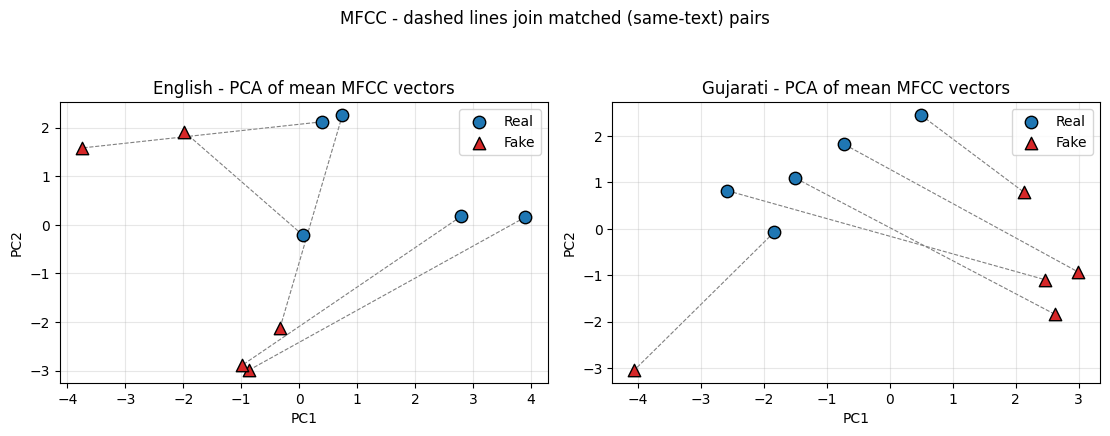

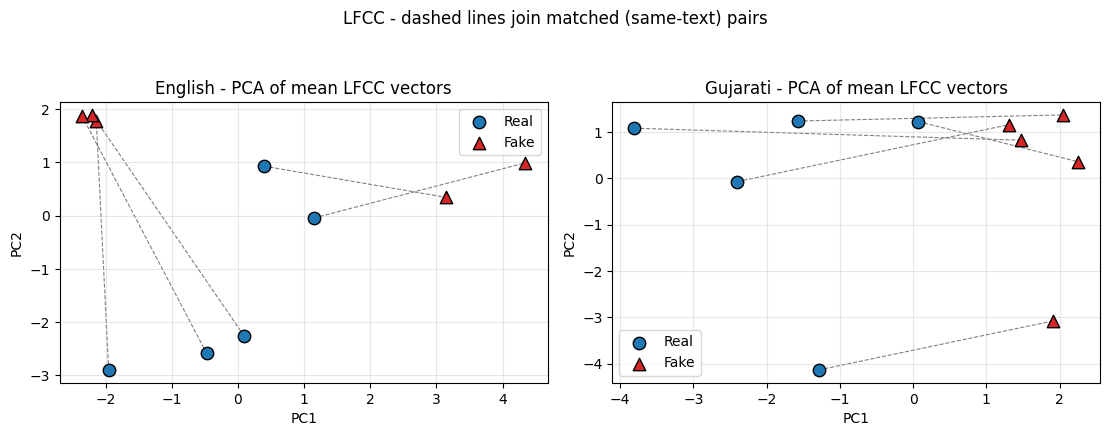

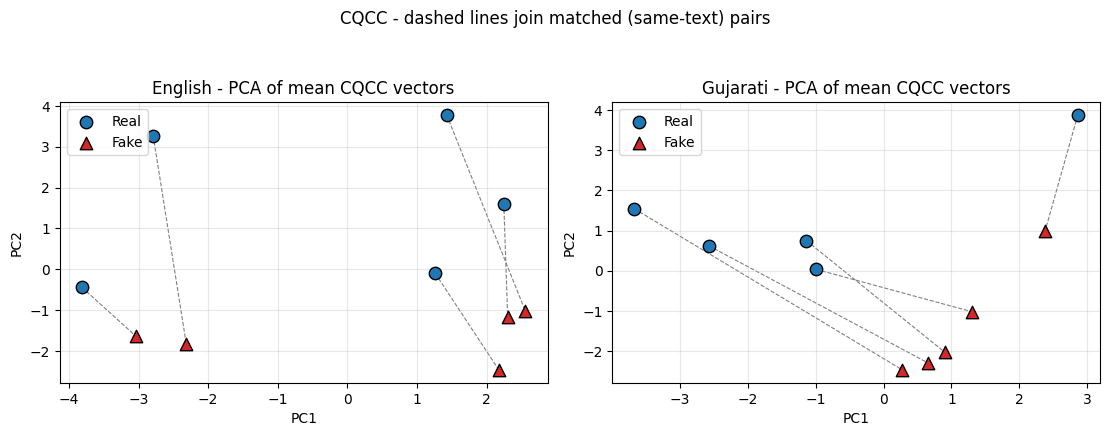

In [23]:
from sklearn.decomposition import PCA


def plot_pca(feature_name):
    langs = [l for l in ("English", "Gujarati")
             if features.get(f"{l} - Real") and features.get(f"{l} - Fake")]
    if not langs:
        return
    fig, axes = plt.subplots(1, len(langs), figsize=(5.6 * len(langs), 4.4), squeeze=False)
    for j, lang in enumerate(langs):
        ax = axes[0][j]
        _, _, per_r = mean_profile(f"{lang} - Real", feature_name)
        _, _, per_f = mean_profile(f"{lang} - Fake", feature_name)
        X = np.vstack([per_r, per_f])
        X = (X - X.mean(axis=0)) / (X.std(axis=0) + 1e-9)
        Z = PCA(n_components=2, random_state=42).fit_transform(X)
        n = len(per_r)
        for i in range(n):                      # join each matched pair
            ax.plot([Z[i, 0], Z[n + i, 0]], [Z[i, 1], Z[n + i, 1]],
                    color="grey", lw=0.8, ls="--", zorder=0)
        ax.scatter(Z[:n, 0], Z[:n, 1], c="#1f77b4", s=80, label="Real", edgecolor="k", zorder=2)
        ax.scatter(Z[n:, 0], Z[n:, 1], c="#d62728", s=80, marker="^", label="Fake",
                   edgecolor="k", zorder=2)
        ax.set_title(f"{lang} - PCA of mean {feature_name.upper()} vectors")
        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(f"{feature_name.upper()} - dashed lines join matched (same-text) pairs", fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.show()


for _f in ("mfcc", "lfcc", "cqcc"):
    plot_pca(_f)

---

# 11. What all of this actually means

*Written for a reader who has not done cepstral analysis before. No unexplained jargon.*

## 11.1 What MFCC, LFCC and CQCC are, and how the code above computes them

All three are **cepstral features**. They all answer the same question — *what shape is the spectrum of
this short slice of sound?* — and they differ only in how they measure the frequency axis before
answering.

The common recipe, exactly as the code performs it:

1. **Framing.** The 4-second waveform is chopped into overlapping slices of `n_fft = 400` samples
   (25 ms) taken every `hop_length = 160` samples (10 ms). 25 ms is short enough that the vocal tract
   is roughly static within a slice, which is what makes the rest of the recipe meaningful. 4 s at a
   10 ms hop gives 398 slices.
2. **Transform.** Each slice goes through a Fourier transform, giving the energy at each frequency —
   a *spectrum*.
3. **Filterbank or CQT.** The raw spectrum has hundreds of frequency bins, most of them redundant. It
   is summarised into a few broad bands:
   - **MFCC** uses **23 mel-spaced** triangular filters. The mel scale is narrow at low frequencies and
     wide at high ones, mimicking human hearing. MFCCs therefore describe the sound roughly the way an
     ear would — good at capturing **vocal-tract shape**, i.e. which vowel or consonant is being
     produced.
   - **LFCC** uses **linearly spaced** filters — equal width everywhere. It does *not* squash the high
     frequencies, so it keeps far more detail up near 8 kHz. That matters because vocoders and neural
     waveform generators tend to leave their fingerprints exactly there: over-smoothed or subtly
     periodic high-frequency energy that a mel filterbank would blur away.
   - **CQCC** replaces the fixed-window Fourier transform with the **Constant-Q Transform**, whose
     filters are *geometrically* spaced — each band a fixed musical interval above the last. It gives
     fine frequency resolution low down and fine time resolution high up. This is the one most sensitive
     to **variable-resolution vocoder errors**, because it inspects the signal at multiple scales at
     once.
4. **Log.** The band energies are compressed logarithmically (`amplitude_to_db` in the CQCC path, the
   internal log in the MFCC/LFCC transforms). Loudness is perceived multiplicatively, and the log turns
   that into addition.
5. **DCT.** A Discrete Cosine Transform (`scipy.fftpack.dct`, type 2, orthonormal) is applied down the
   frequency axis, and the **first 13** outputs are kept. The DCT decorrelates the band energies and
   sorts them by "how wiggly": coefficient 0 is overall level, coefficient 1 is the broad tilt of the
   spectrum, and higher indices describe progressively finer ripple in the spectral envelope.

So each clip becomes a **13 × 398 matrix**: 13 numbers describing spectral shape, recomputed every
10 ms. That matrix is what the heatmaps in Section 8 draw, and what the ResNeXt branches will consume.

## 11.2 Why matching the *exact spoken content* is the whole point

A cepstral coefficient does not know whether it is looking at a synthesis artefact. It reports spectral
shape, and spectral shape changes when *anything* changes — the words, the speaker, the microphone, the
room, the length of the clip.

In the exploratory notebook, the Gujarati "real" clips came from FLEURS (one set of speakers, one
recording protocol, mean length 11.44 s) and the Gujarati "fake" clips came from IndicSynth (different
text, different voices, mean length 5.44 s). If those two sets of heatmaps look different — and they do
— **we cannot say why**. Different sentences alone would produce different heatmaps. So would a 2.1×
difference in duration. The synthesis artefact was tangled up with at least three other explanations.

This notebook removes them one at a time:

| Confound | How it is removed here |
|---|---|
| Different words | The fake is TTS of the real clip's **exact transcript** |
| Different language / corpus | Both languages come from **FLEURS**, same protocol |
| Different clip length | Every clip is forced to **exactly 4.0 s / 64,000 samples** |
| Different speaker gender | The TTS voice is picked to **match the FLEURS speaker's gender** |

What is left over after all four are held constant is, as far as this design can isolate it, the
difference between *a human saying these words* and *a neural vocoder rendering these words*. This is
the same logic Kulangareth et al. used when they recorded control paragraphs and then cloned **those
same paragraphs**, rather than comparing arbitrary recordings — matched content is what makes a
difference interpretable.

## 11.3 How to read the mean-coefficient line plots (Section 9)

Each plot has a blue line (Real) and a red line (Fake), with 13 points each — one per coefficient index,
averaged over all 398 time frames and then over all 5 clips. The shaded band is ±1 standard deviation
across those 5 clips.

- **Where the two lines separate and the bands do not overlap** → that coefficient index carries
  information that distinguishes real from synthetic. The Real and Fake populations genuinely sit at
  different values there, and the separation is larger than ordinary clip-to-clip variation.
- **Where the two lines sit on top of each other** → that coefficient is not useful on its own for this
  distinction. It is describing something a human and a vocoder do identically.
- **Where the lines separate but the bands overlap heavily** → suggestive, but 5 clips is not enough to
  call it. Section 10's Cohen's *d* is exactly this judgement expressed as a number: |d| below ~0.5 is
  small, ~0.8 is conventionally "large", and with n = 5 even a large *d* is a weak estimate.
- **Low indices (0–3) vs high indices (7–12).** Low coefficients describe overall level and gross
  spectral tilt — these often differ simply because a TTS voice has different gain and a flatter,
  cleaner spectrum than a room-recorded human. High coefficients describe fine ripple in the spectral
  envelope, which is where vocoder over-smoothing tends to show up. Separation at high indices is the
  more interesting kind.

## 11.4 How this connects to the Triple-Branch ResNeXt classifier

The line plots throw away almost everything: they collapse 398 time frames into one average. The
classifier does not. Each of the three ResNeXt branches receives the **full 13 × 398 matrix** for its
own feature and slides small convolutional filters over it, so it can learn:

- **coefficient-level** differences — the same vertical structure the line plots show, but learned
  rather than eyeballed, and learned as *combinations* of coefficients instead of one at a time;
- **temporal-texture** differences — how each coefficient *moves* across the clip. Human speech has
  micro-jitter, breath, and irregular transitions between phonemes; vocoder output tends to be smoother
  and more regular. That is entirely invisible in a time-average and entirely visible to a convolution.

The MLP fusion layer then combines the three branch embeddings, which is what lets the model use each
feature where it is strongest — CQCC against TTS/VC artefacts, LFCC as the consistent all-rounder,
MFCC for vocal-tract-level cues, following Tahaoglu et al.'s finding.

So: **the plots in this notebook are a human-readable preview of the signal the convolutional filters
are being asked to find automatically.** If Real and Fake were indistinguishable even in these
collapsed averages, that would be a warning sign for the architecture. Visible separation here is
encouraging, but it is not a detection result.

## 11.5 What this notebook is *not*

Stated plainly, because it matters:

- **5 clips per category is a diagnostic sample, not a dataset.** It cannot train a model, cannot
  validate one, and cannot support a significance claim. Every effect size in Section 10 is descriptive.
- **No classifier was trained, so there is no EER, no accuracy, and no confusion matrix here.** The
  `EER < 5%` figure in our proposal is a *target*, and the 30–50% cross-lingual degradation figure comes
  from the literature — neither is a measurement of our system.
- **The fakes are our own edge-tts renderings**, not ASVspoof's A01–A19 attacks or IndicSynth's
  systems. One TTS engine's artefacts are not all TTS artefacts. A model that separates these two
  classes has not thereby been shown to generalise.
- **The 4-second windows are text-matched but not time-aligned.** A human speaker and a TTS voice read
  the same sentence at different rates, so the two 4 s windows do not cover identical words. Choosing
  the shortest available utterances limits this, but does not eliminate it. Forced alignment (e.g. via
  an ASR aligner) would be the proper fix.
- **Only Gujarati is covered on the Indic side.** Hindi is in the proposal and not yet implemented.

Formal evaluation still requires the full roadmap: base training of the Triple-Branch ResNeXt on
ASVspoof 2019 LA, zero-shot testing on Gujarati and Hindi to measure the EER spike, and MLP fine-tuning
for target adaptation.